# Workshop 3 — EDA and Data Curation Pipeline

This notebook applies the course data curation pipeline to the project's historical data:

**Raw data (Bronze) → EDA and profiling → outlier detection → missing-value imputation → feature engineering → feature selection → curated layer**

It follows the structure of the course notebooks *EDA & Data Curation* and *Data Visualization Gallery*. No machine-learning step is used: outliers are found with statistical rules, missing values are filled with group medians, and features are selected with filters.

**Uniform input.** Every result comes from one Bronze run committed in `datalake_bronze/samples/historical_20261117_001544/` (16 yearly USGS FDSN files and 2 NOAA HazEL pages, 2010–2025). The notebook therefore gives the same output on every laptop, independently of when each one polled the real-time feeds.

**Scope of the curated data.** The curated files are an analysis layer. Imputed values are stored in separate columns with a flag, and they are never used by the event matching, the canonical database or the Tsunami Relevance Level.

## 1. Setup and Raw Data (Bronze)

In [1]:
%matplotlib inline

import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 11, "axes.labelsize": 9})
pd.set_option("display.max_columns", 40, "display.width", 160)

root = Path.cwd().resolve()
if root.name == "notebooks":
    root = root.parent
bronze = root / "datalake_bronze" / "samples" / "historical_20261117_001544"

usgs_raw = pd.concat([pd.read_csv(path) for path in sorted(bronze.glob("usgs_fdsn_*.csv"))], ignore_index=True)
noaa_items = []
for path in sorted(bronze.glob("noaa_hazel_page*.json")):
    noaa_items += json.loads(path.read_text(encoding="utf-8"))["items"]
noaa_raw = pd.DataFrame(noaa_items)

print(f"USGS FDSN earthquakes: {usgs_raw.shape[0]:,} rows x {usgs_raw.shape[1]} columns")
print(f"NOAA HazEL tsunamis:   {noaa_raw.shape[0]:,} rows x {noaa_raw.shape[1]} columns")

USGS FDSN earthquakes: 1,930 rows x 22 columns
NOAA HazEL tsunamis:   221 rows x 50 columns


## 2. EDA — Profiling

Data types, missing values, unique values and duplicates, before any change.

In [2]:
def profile(frame):
    return pd.DataFrame({
        "dtype": frame.dtypes.astype(str), "missing": frame.isna().sum(),
        "missing_%": (100 * frame.isna().mean()).round(1), "unique": frame.nunique(),
        "example": [frame[c].dropna().iloc[0] if frame[c].notna().any() else None for c in frame],
    })


print("USGS FDSN")
display(profile(usgs_raw))
print("NOAA HazEL (columns used by the project)")
noaa_used = ["id", "year", "month", "day", "hour", "minute", "second", "latitude", "longitude", "causeCode",
             "eventValidity", "regionCode", "eqMagnitude", "eqDepth", "maxWaterHeight", "numRunups", "country"]
display(profile(noaa_raw[noaa_used]))
print("Duplicate ids: USGS", usgs_raw["id"].duplicated().sum(), "| NOAA", noaa_raw["id"].duplicated().sum())
print("USGS event types:", usgs_raw["type"].value_counts().to_dict())

USGS FDSN


,dtype,missing,missing_%,unique,example
time,object,0,0.0,1930,2010-12-29T06:54:19.640Z
latitude,float64,0,0.0,1928,-19.661
longitude,float64,0,0.0,1924,168.14
depth,float64,0,0.0,669,16.0
mag,float64,0,0.0,28,6.4
magType,object,0,0.0,8,mwc
nst,float64,1000,51.8,487,372.0
gap,float64,16,0.8,375,20.2
dmin,float64,536,27.8,1234,0.5137
rms,float64,9,0.5,130,1.27


NOAA HazEL (columns used by the project)


,dtype,missing,missing_%,unique,example
id,int64,0,0.0,221,4522
year,int64,0,0.0,16,2010
month,int64,0,0.0,12,1
day,int64,0,0.0,31,3
hour,float64,23,10.4,24,21.0
minute,float64,23,10.4,55,48.0
second,float64,32,14.5,145,5.3
latitude,float64,9,4.1,210,-8.743
longitude,float64,9,4.1,210,157.477
causeCode,int64,0,0.0,8,1


Duplicate ids: USGS 0 | NOAA 0
USGS event types: {'earthquake': 1929, 'nuclear explosion': 1}


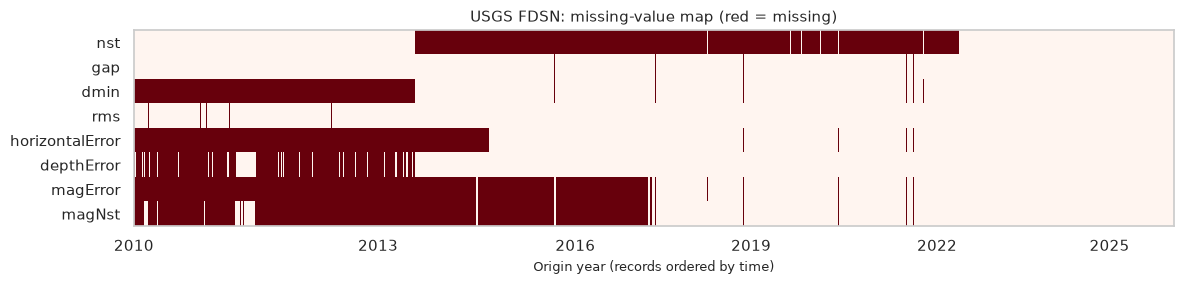

In [3]:
# Missing-value map ordered by date: missing values are not scattered, they come in blocks of years
ordered = usgs_raw.sort_values("time").reset_index(drop=True)
quality = ["nst", "gap", "dmin", "rms", "horizontalError", "depthError", "magError", "magNst"]
fig, ax = plt.subplots(figsize=(12, 3))
ax.imshow(ordered[quality].isna().T, aspect="auto", cmap="Reds", interpolation="nearest")
ax.set_yticks(range(len(quality)), quality)
years = pd.to_datetime(ordered["time"], format="ISO8601").dt.year
ticks = [years.searchsorted(y) for y in range(2010, 2026, 3)]
ax.set_xticks(ticks, range(2010, 2026, 3))
ax.set(xlabel="Origin year (records ordered by time)", title="USGS FDSN: missing-value map (red = missing)")
ax.grid(False)
plt.tight_layout(); plt.show()

## 3. EDA — Univariate Analysis

Histograms with a density curve and box plots for the numeric variables, bar charts for the categorical ones. Working copies get clear names and types; values are not changed yet.

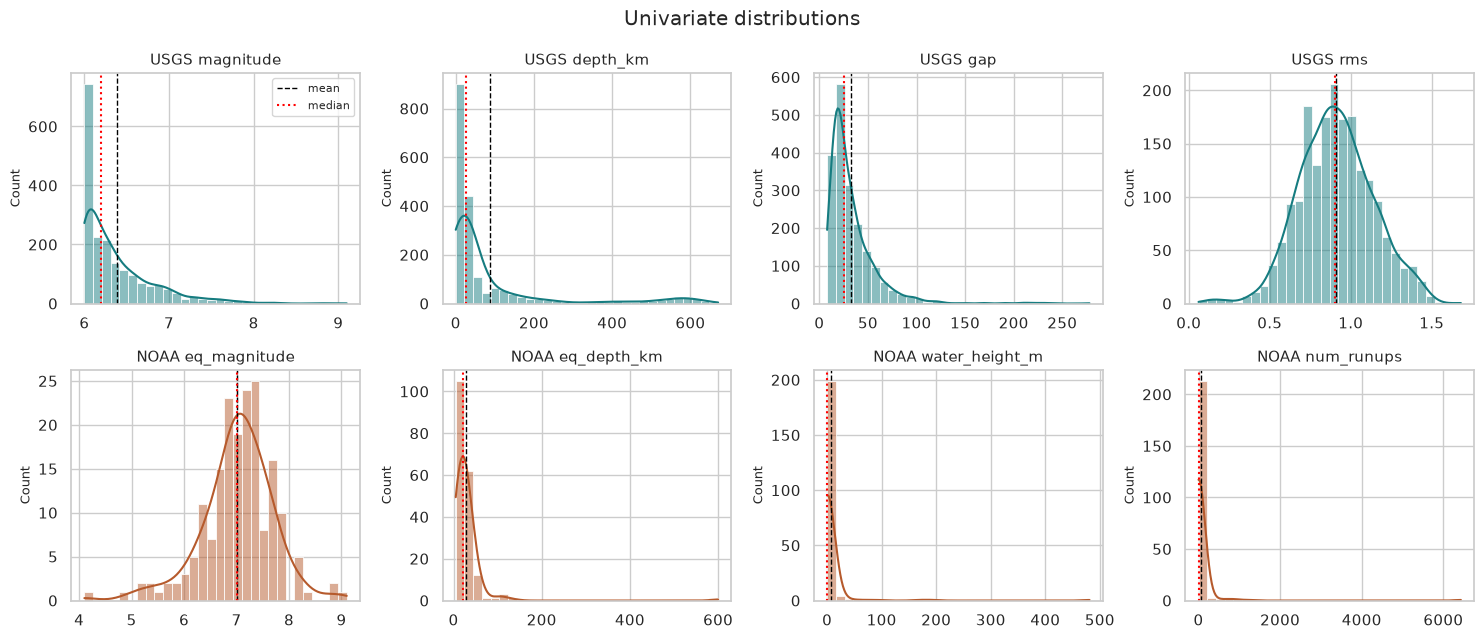

In [4]:
usgs = usgs_raw.rename(columns={"mag": "magnitude", "depth": "depth_km", "magType": "magnitude_type"}).copy()
usgs["time"] = pd.to_datetime(usgs["time"], format="ISO8601", utc=True)
usgs["year"] = usgs["time"].dt.year
noaa = noaa_raw[noaa_used].rename(columns={
    "eqMagnitude": "eq_magnitude", "eqDepth": "eq_depth_km", "maxWaterHeight": "water_height_m",
    "numRunups": "num_runups", "causeCode": "cause_code", "eventValidity": "validity"}).copy()

USGS_NUM = ["magnitude", "depth_km", "gap", "rms", "dmin", "horizontalError", "depthError", "magError", "nst", "magNst"]
NOAA_NUM = ["eq_magnitude", "eq_depth_km", "water_height_m", "num_runups"]

fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
for ax, (frame, column) in zip(axes.flat, [(usgs, c) for c in ["magnitude", "depth_km", "gap", "rms"]]
                               + [(noaa, c) for c in NOAA_NUM]):
    values = frame[column].dropna()
    sns.histplot(values, bins=30, kde=True, ax=ax, color="#167c80" if frame is usgs else "#b65a2c")
    ax.axvline(values.mean(), color="black", ls="--", lw=1, label="mean")
    ax.axvline(values.median(), color="red", ls=":", lw=1.5, label="median")
    ax.set(title=("USGS " if frame is usgs else "NOAA ") + column, xlabel="", ylabel="Count")
axes.flat[0].legend(fontsize=8)
plt.suptitle("Univariate distributions"); plt.tight_layout(); plt.show()

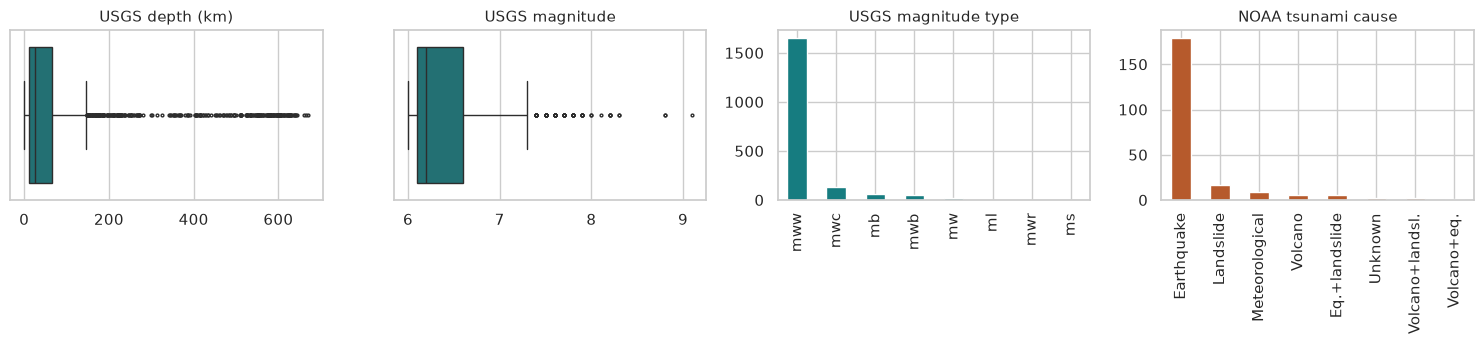

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
sns.boxplot(x=usgs["depth_km"], ax=axes[0], color="#167c80", fliersize=2).set(title="USGS depth (km)", xlabel="")
sns.boxplot(x=usgs["magnitude"], ax=axes[1], color="#167c80", fliersize=2).set(title="USGS magnitude", xlabel="")
usgs["magnitude_type"].value_counts().plot.bar(ax=axes[2], color="#167c80", title="USGS magnitude type", xlabel="")
cause_names = {0: "Unknown", 1: "Earthquake", 3: "Eq.+landslide", 4: "Volcano+eq.", 6: "Volcano",
               7: "Volcano+landsl.", 8: "Landslide", 9: "Meteorological"}
noaa["cause"] = noaa["cause_code"].map(cause_names)
noaa["cause"].value_counts().plot.bar(ax=axes[3], color="#b65a2c", title="NOAA tsunami cause", xlabel="")
plt.tight_layout(); plt.show()

## 4. EDA — Central Tendency, Dispersion and Shape

Mean and median, standard deviation, variance, IQR and range, with skewness and excess kurtosis (0 for a normal distribution). A large gap between mean and median is a first sign of skewness or outliers.

In [6]:
def describe_shape(frame, columns, dataset):
    rows = []
    for column in columns:
        s = frame[column].dropna()
        q1, q3 = s.quantile([0.25, 0.75])
        rows.append({"dataset": dataset, "variable": column, "n": len(s), "mean": s.mean(), "median": s.median(),
                     "std": s.std(), "variance": s.var(), "IQR": q3 - q1, "range": s.max() - s.min(),
                     "P95": s.quantile(0.95), "skewness": stats.skew(s), "kurtosis": stats.kurtosis(s)})
    return pd.DataFrame(rows)


summary = pd.concat([describe_shape(usgs, USGS_NUM, "USGS"), describe_shape(noaa, NOAA_NUM, "NOAA")], ignore_index=True)
display(summary.round(2))
strong = summary.loc[summary["skewness"].abs() > 1, ["dataset", "variable", "skewness"]].round(2)
print("Variables with |skewness| > 1:", ", ".join(f"{r.dataset} {r.variable} ({r.skewness})" for r in strong.itertuples()))

,dataset,variable,n,mean,median,std,variance,IQR,range,P95,skewness,kurtosis
0,USGS,magnitude,1930,6.38,6.20,0.43,0.18,0.50,3.10,7.30,1.74,3.74
1,USGS,depth_km,1930,88.57,26.00,153.07,23431.18,54.00,670.81,549.96,2.46,4.89
2,USGS,gap,1914,33.03,25.00,24.93,621.50,22.00,270.00,76.24,3.40,19.55
3,USGS,rms,1921,0.91,0.90,0.23,0.05,0.31,1.62,1.31,-0.00,0.25
4,USGS,dmin,1394,3.02,2.05,3.74,13.97,2.72,31.55,7.50,4.63,27.65
5,USGS,horizontalError,1263,6.79,6.90,1.90,3.62,2.30,14.00,9.62,-0.35,0.92
6,USGS,depthError,1496,2.38,1.80,2.18,4.74,0.23,31.61,4.60,8.38,95.08
7,USGS,magError,971,0.05,0.04,0.02,0.00,0.02,0.51,0.07,11.73,249.32
8,USGS,nst,930,310.60,276.00,180.66,32636.97,287.50,924.00,643.30,0.66,-0.22
9,USGS,magNst,1022,63.71,48.00,74.29,5519.60,35.00,941.00,155.95,6.28,52.66


Variables with |skewness| > 1: USGS magnitude (1.74), USGS depth_km (2.46), USGS gap (3.4), USGS dmin (4.63), USGS depthError (8.38), USGS magError (11.73), USGS magNst (6.28), NOAA eq_depth_km (10.35), NOAA water_height_m (10.12), NOAA num_runups (12.96)


## 5. EDA — Bivariate Analysis

Pearson measures linear association and is sensitive to outliers; Spearman uses ranks and is robust. With these skewed variables the two can differ, so both are shown. Each pair uses the records where both values exist. Correlation is not causation.

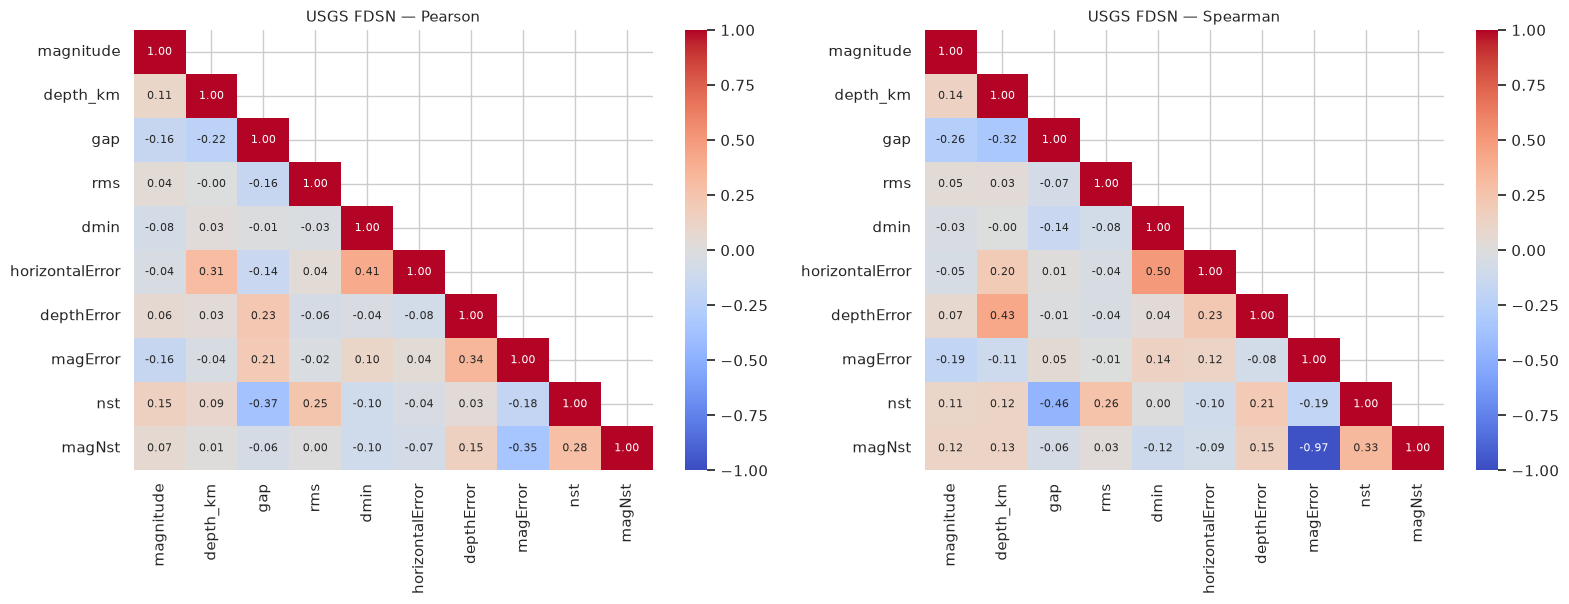

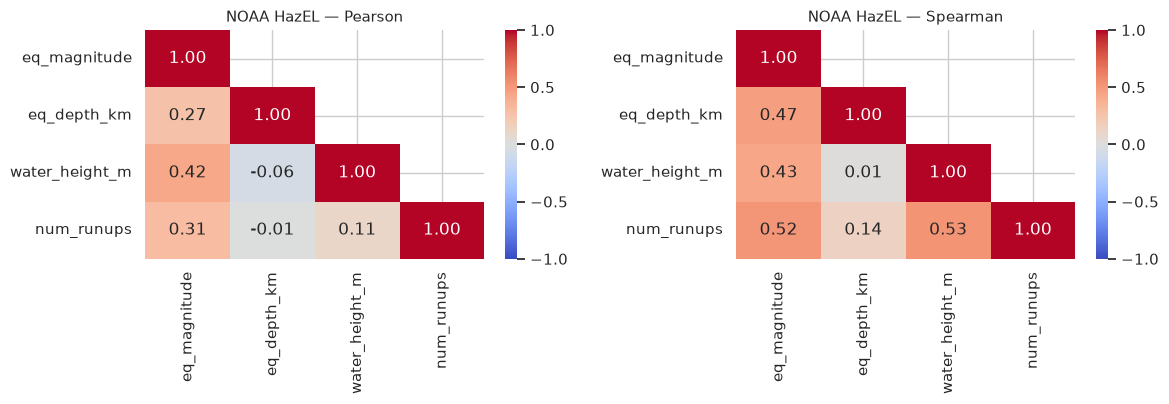

,dataset,pair,n,Pearson r,Spearman rho
0,USGS,magError / magNst,970,-0.35,-0.97
1,NOAA,water_height_m / num_runups,209,0.11,0.53
2,NOAA,eq_magnitude / num_runups,186,0.31,0.52
3,USGS,dmin / horizontalError,1260,0.41,0.50
4,NOAA,eq_magnitude / eq_depth_km,186,0.27,0.47
5,USGS,gap / nst,930,-0.37,-0.46
6,NOAA,eq_magnitude / water_height_m,179,0.42,0.43
7,USGS,depth_km / depthError,1496,0.03,0.43


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.2))
for ax, method in zip(axes, ["pearson", "spearman"]):
    corr = usgs[USGS_NUM].corr(method=method)
    sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool), k=1), annot=True, fmt=".2f", cmap="coolwarm",
                center=0, vmin=-1, vmax=1, annot_kws={"size": 8}, ax=ax)
    ax.set_title(f"USGS FDSN — {method.title()}")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, method in zip(axes, ["pearson", "spearman"]):
    corr = noaa[NOAA_NUM].corr(method=method)
    sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool), k=1), annot=True, fmt=".2f", cmap="coolwarm",
                center=0, vmin=-1, vmax=1, ax=ax)
    ax.set_title(f"NOAA HazEL — {method.title()}")
plt.tight_layout(); plt.show()

rows = []
for name, frame, columns in [("USGS", usgs, USGS_NUM), ("NOAA", noaa, NOAA_NUM)]:
    for i, a in enumerate(columns):
        for b in columns[i + 1:]:
            pair = frame[[a, b]].dropna()
            rows.append((name, f"{a} / {b}", len(pair), stats.pearsonr(pair[a], pair[b])[0], stats.spearmanr(pair[a], pair[b])[0]))
pairs = pd.DataFrame(rows, columns=["dataset", "pair", "n", "Pearson r", "Spearman rho"])
display(pairs.loc[pairs["Spearman rho"].abs() >= 0.4].sort_values("Spearman rho", key=abs, ascending=False).round(2).reset_index(drop=True))

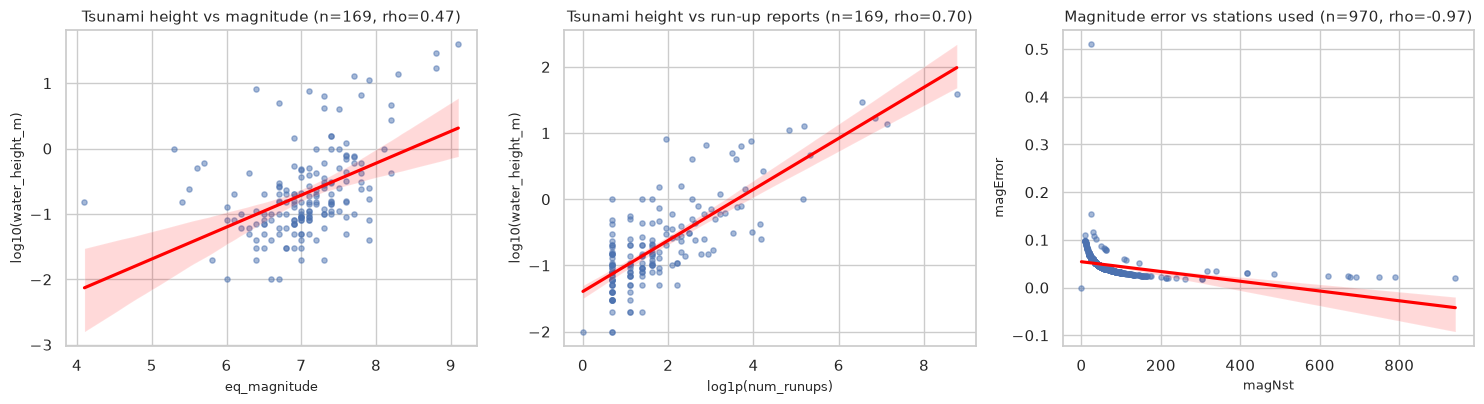

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
earthquake_tsunamis = noaa[noaa["cause_code"].eq(1) & noaa["validity"].isin([3, 4])]
for ax, (frame, x, y, logy, title) in zip(axes, [
        (earthquake_tsunamis, "eq_magnitude", "water_height_m", True, "Tsunami height vs magnitude"),
        (earthquake_tsunamis, "num_runups", "water_height_m", True, "Tsunami height vs run-up reports"),
        (usgs, "magNst", "magError", False, "Magnitude error vs stations used")]):
    d = frame[[x, y]].dropna()
    d = d[(d[y] > 0)] if logy else d
    xs = np.log1p(d[x]) if x == "num_runups" else d[x]
    ys = np.log10(d[y]) if logy else d[y]
    sns.regplot(x=xs, y=ys, ax=ax, scatter_kws={"s": 14, "alpha": 0.5}, line_kws={"color": "red"})
    rho = stats.spearmanr(d[x], d[y])[0]
    ax.set(title=f"{title} (n={len(d)}, rho={rho:.2f})", xlabel=f"log1p({x})" if x == "num_runups" else x,
           ylabel=f"log10({y})" if logy else y)
plt.tight_layout(); plt.show()

## 6. EDA — Multivariate Analysis

Pair plot, bubble map and small multiples show three or more variables at once. The partial Spearman correlation then checks whether a relation remains after removing the effect of a third variable.

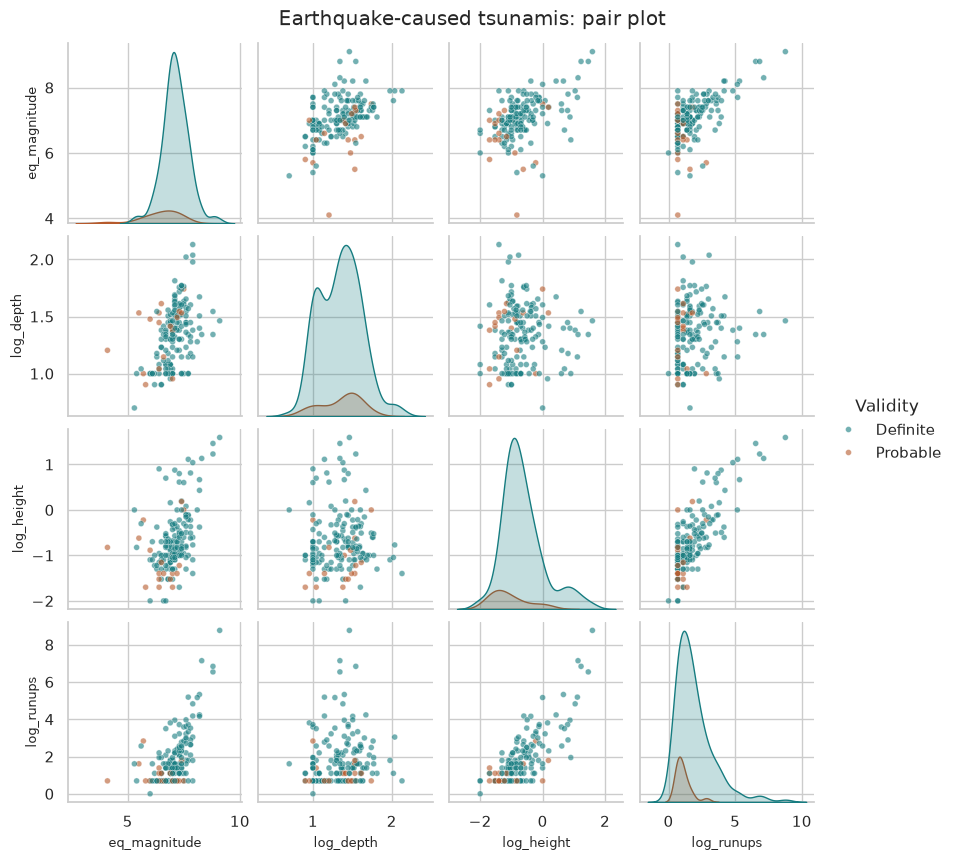

In [9]:
pp = earthquake_tsunamis.assign(
    log_height=np.log10(earthquake_tsunamis["water_height_m"].where(earthquake_tsunamis["water_height_m"] > 0)),
    log_depth=np.log10(earthquake_tsunamis["eq_depth_km"]),
    log_runups=np.log1p(earthquake_tsunamis["num_runups"]),
    Validity=earthquake_tsunamis["validity"].map({3: "Probable", 4: "Definite"}))
grid = sns.pairplot(pp[["eq_magnitude", "log_depth", "log_height", "log_runups", "Validity"]].dropna(), hue="Validity",
                    diag_kind="kde", palette={"Probable": "#b65a2c", "Definite": "#167c80"},
                    plot_kws={"alpha": 0.6, "s": 18}, height=2.1)
grid.figure.suptitle("Earthquake-caused tsunamis: pair plot", y=1.02)
plt.show()

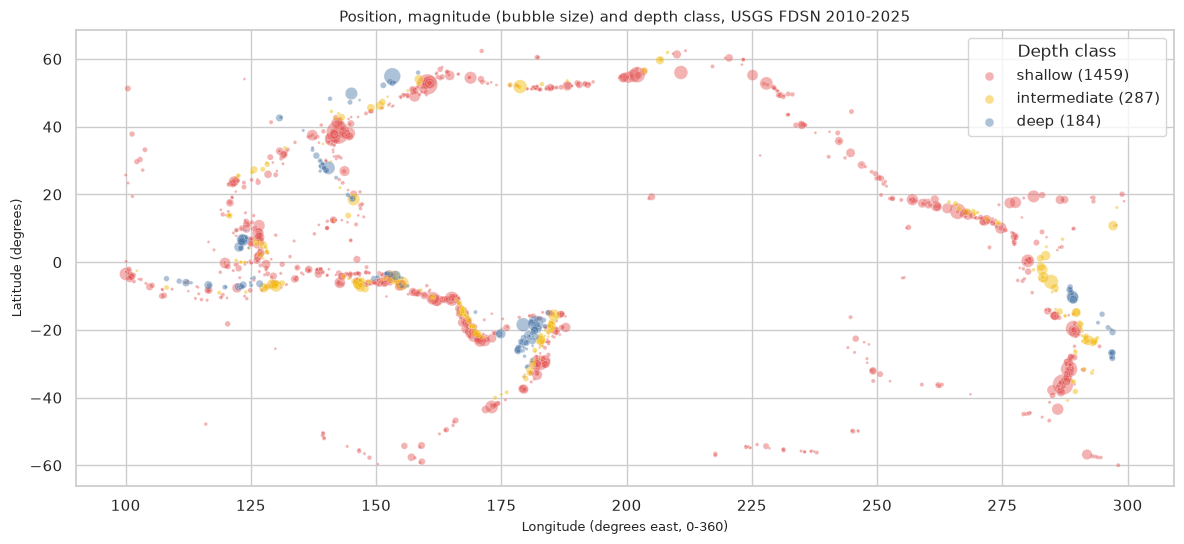

In [10]:
usgs["depth_class"] = pd.cut(usgs["depth_km"], [-np.inf, 70, 300, np.inf], labels=["shallow", "intermediate", "deep"])
colors = {"shallow": "#e45756", "intermediate": "#f2b701", "deep": "#4c78a8"}
fig, ax = plt.subplots(figsize=(12, 5.6))
lon360 = usgs["longitude"].where(usgs["longitude"] >= 0, usgs["longitude"] + 360)
for name, color in colors.items():
    rows = usgs["depth_class"].eq(name)
    ax.scatter(lon360[rows], usgs.loc[rows, "latitude"], s=4 * (usgs.loc[rows, "magnitude"] - 5) ** 3, color=color,
               alpha=0.45, edgecolor="white", lw=0.3, label=f"{name} ({rows.sum()})")
ax.set(xlabel="Longitude (degrees east, 0-360)", ylabel="Latitude (degrees)",
       title="Position, magnitude (bubble size) and depth class, USGS FDSN 2010-2025")
legend = ax.legend(title="Depth class")
for handle in legend.legend_handles:
    handle.set_sizes([40])
plt.tight_layout(); plt.show()

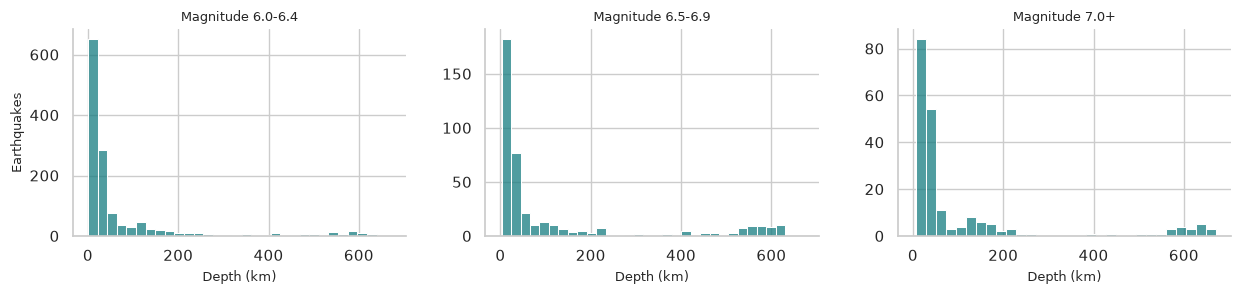

depth_class,shallow,intermediate,deep,n
magnitude_class,,,,
6.0-6.4,77.6,14.9,7.5,1323
6.5-6.9,70.4,14.2,15.4,402
7.0+,72.7,16.1,11.2,205


,pair,controlling for,n,Spearman,partial Spearman
0,eq_magnitude / water_height_m,eq_depth_km,170,0.47,0.49
1,eq_magnitude / water_height_m,num_runups,170,0.47,0.12
2,num_runups / water_height_m,eq_magnitude,170,0.70,0.60
3,eq_depth_km / water_height_m,eq_magnitude,170,0.08,-0.18


num_runups is partly a consequence of the size of the tsunami, so controlling for it removes part of the real effect of magnitude.


In [11]:
usgs["magnitude_class"] = pd.cut(usgs["magnitude"], [5.9, 6.5, 7, 10], right=False, labels=["6.0-6.4", "6.5-6.9", "7.0+"])
facet = sns.FacetGrid(usgs, col="magnitude_class", height=3.1, aspect=1.35, sharey=False)
facet.map(sns.histplot, "depth_km", bins=30, color="#167c80")
facet.set_titles("Magnitude {col_name}"); facet.set_axis_labels("Depth (km)", "Earthquakes")
plt.show()
display(pd.crosstab(usgs["magnitude_class"], usgs["depth_class"], normalize="index").mul(100).round(1)
        .assign(n=usgs["magnitude_class"].value_counts()))


def partial_spearman(frame, x, y, control):
    """Spearman correlation of x and y after removing the rank effect of the control variable."""
    r = frame[[x, y, control]].dropna().rank()
    residual = lambda a: r[a] - np.polyval(np.polyfit(r[control], r[a], 1), r[control])
    return stats.pearsonr(residual(x), residual(y))[0], len(r)


partial_rows = []
for x, y, control in [("eq_magnitude", "water_height_m", "eq_depth_km"), ("eq_magnitude", "water_height_m", "num_runups"),
                      ("num_runups", "water_height_m", "eq_magnitude"), ("eq_depth_km", "water_height_m", "eq_magnitude")]:
    d = earthquake_tsunamis[[x, y, control]].dropna()
    value, n = partial_spearman(earthquake_tsunamis, x, y, control)
    partial_rows.append((f"{x} / {y}", control, n, stats.spearmanr(d[x], d[y])[0], value))
display(pd.DataFrame(partial_rows, columns=["pair", "controlling for", "n", "Spearman", "partial Spearman"]).round(2))
print("num_runups is partly a consequence of the size of the tsunami, so controlling for it removes part of the real effect of magnitude.")

## 7. Data Quality Dimensions

Every issue found is documented before anything is treated, using the seven dimensions of the course.

In [12]:
n_usgs, n_noaa = len(usgs), len(noaa)
no_time = int(noaa["second"].isna().sum())
eq_causes = noaa["cause_code"].isin([1, 3, 4])
issues = [
    ("Accuracy", "USGS", f"{int((usgs['type'] != 'earthquake').sum())} record is not an earthquake ({', '.join(usgs.loc[usgs['type'] != 'earthquake', 'type'])})", "Remove"),
    ("Completeness", "USGS", "; ".join(f"{c} {usgs[c].isna().mean():.0%}" for c in quality if usgs[c].isna().mean() > 0.05), "Section 10"),
    ("Completeness", "NOAA", f"water height {noaa['water_height_m'].isna().mean():.1%}; coordinates {noaa['latitude'].isna().mean():.1%}; "
                             f"magnitude and depth {noaa['eq_magnitude'].isna().mean():.1%}", "Section 10"),
    ("Consistency", "USGS", f"{usgs['magnitude_type'].nunique()} magnitude types in one column", "Keep type; group rare types"),
    ("Timeliness", "Both", f"USGS {usgs['time'].min():%Y-%m-%d} to {usgs['time'].max():%Y-%m-%d}; NOAA {noaa['year'].min()} to {noaa['year'].max()}", "Fixed period"),
    ("Uniqueness", "Both", f"{usgs['id'].duplicated().sum() + noaa['id'].duplicated().sum()} duplicate ids in one run", "None needed"),
    ("Validity", "NOAA", f"{int(noaa['validity'].eq(-1).sum())} erroneous entry, {int(noaa['validity'].eq(2).sum())} questionable", "Flag, exclude from tsunami statistics"),
    ("Validity", "NOAA", f"{no_time} events without a full time", "Keep precision, never invent a time"),
    ("Integrity", "NOAA", f"magnitude missing in {int(noaa.loc[eq_causes, 'eq_magnitude'].isna().sum())} of {int(eq_causes.sum())} earthquake-caused events "
                          f"and {int(noaa.loc[~eq_causes, 'eq_magnitude'].isna().sum())} of {int((~eq_causes).sum())} others", "Structural, do not impute"),
]
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(issues, columns=["Dimension", "Dataset", "Issue", "Treatment"]))

,Dimension,Dataset,Issue,Treatment
0,Accuracy,USGS,1 record is not an earthquake (nuclear explosion),Remove
1,Completeness,USGS,nst 52%; dmin 28%; horizontalError 35%; depthError 22%; magError 50%; magNst 47%,Section 10
2,Completeness,NOAA,water height 5.4%; coordinates 4.1%; magnitude and depth 15.8%,Section 10
3,Consistency,USGS,8 magnitude types in one column,Keep type; group rare types
4,Timeliness,Both,USGS 2010-01-02 to 2025-12-31; NOAA 2010 to 2025,Fixed period
5,Uniqueness,Both,0 duplicate ids in one run,None needed
6,Validity,NOAA,"1 erroneous entry, 8 questionable","Flag, exclude from tsunami statistics"
7,Validity,NOAA,32 events without a full time,"Keep precision, never invent a time"
8,Integrity,NOAA,magnitude missing in 0 of 185 earthquake-caused events and 35 of 36 others,"Structural, do not impute"


## 8. Outlier Detection

Three statistical rules: **Z-score** (|z| > 3, assumes normality), **IQR** (beyond 1.5 IQR from the quartiles, robust) and **Mahalanobis distance** (multivariate, compared with a chi-square limit at 99 %). The Mahalanobis distance replaces the Isolation Forest of the course notebook because no machine learning is used; it runs on the log-transformed variables.

In [13]:
usgs_clean = usgs[usgs["type"].eq("earthquake")].drop_duplicates("id").reset_index(drop=True)
print(f"Removed {len(usgs) - len(usgs_clean)} non-earthquake record; {len(usgs_clean):,} earthquakes remain.")


def outlier_masks(s):
    z = (s - s.mean()) / s.std()
    q1, q3 = s.quantile([0.25, 0.75])
    return z.abs() > 3, (s < q1 - 1.5 * (q3 - q1)) | (s > q3 + 1.5 * (q3 - q1))


rows = []
for name, frame, columns in [("USGS", usgs_clean, ["magnitude", "depth_km", "gap", "rms", "dmin", "horizontalError", "depthError"]),
                             ("NOAA", noaa, NOAA_NUM)]:
    for column in columns:
        s = frame[column]
        z_mask, iqr_mask = outlier_masks(s)
        logs = np.log1p(s) if s.min() >= 0 else s
        rows.append((name, column, int(s.notna().sum()), int(z_mask.sum()), int(iqr_mask.sum()),
                     round(100 * iqr_mask.sum() / s.notna().sum(), 1), int(outlier_masks(logs)[1].sum()), s.max()))
display(pd.DataFrame(rows, columns=["dataset", "variable", "n", "Z-score", "IQR", "IQR %", "IQR after log1p", "max"]).round(2))


def mahalanobis(frame):
    d = frame.dropna()
    centered = d - d.mean()
    inverse = np.linalg.inv(np.cov(centered.T))
    distance2 = np.einsum("ij,jk,ik->i", centered.to_numpy(), inverse, centered.to_numpy())
    return pd.Series(distance2, index=d.index), stats.chi2.ppf(0.99, d.shape[1])


usgs_mv = pd.DataFrame({"magnitude": usgs_clean["magnitude"], "log_depth": np.log1p(usgs_clean["depth_km"]),
                        "log_gap": np.log1p(usgs_clean["gap"]), "rms": usgs_clean["rms"]})
noaa_mv = pd.DataFrame({"eq_magnitude": noaa["eq_magnitude"], "log_depth": np.log1p(noaa["eq_depth_km"]),
                        "log_height": np.log1p(noaa["water_height_m"]), "log_runups": np.log1p(noaa["num_runups"])})
for name, frame in [("USGS", usgs_mv), ("NOAA", noaa_mv)]:
    distance2, limit = mahalanobis(frame)
    print(f"{name}: {int((distance2 > limit).sum())} of {len(distance2)} records beyond the 99% chi-square limit ({limit:.1f})")
    top = distance2.nlargest(3).index
    display((usgs_clean.loc[top, ["id", "time", "place", "magnitude", "depth_km", "gap", "rms"]] if name == "USGS"
             else noaa.loc[top, ["id", "year", "country", "cause", "eq_magnitude", "eq_depth_km", "water_height_m", "num_runups"]])
            .assign(mahalanobis2=distance2.loc[top].round(1)))

Removed 1 non-earthquake record; 1,929 earthquakes remain.


,dataset,variable,n,Z-score,IQR,IQR %,IQR after log1p,max
0,USGS,magnitude,1929,34,80,4.1,64,9.10
1,USGS,depth_km,1929,99,297,15.4,0,670.81
2,USGS,gap,1913,28,105,5.5,15,278.00
3,USGS,rms,1920,12,16,0.8,19,1.68
4,USGS,dmin,1393,23,58,4.2,21,31.56
5,USGS,horizontalError,1262,16,33,2.6,52,14.00
6,USGS,depthError,1495,22,386,25.8,387,31.61
7,NOAA,eq_magnitude,186,3,11,5.9,12,9.10
8,NOAA,eq_depth_km,186,1,7,3.8,1,600.00
9,NOAA,water_height_m,209,3,33,15.8,33,481.00


USGS: 38 of 1904 records beyond the 99% chi-square limit (13.3)


,id,time,place,magnitude,depth_km,gap,rms,mahalanobis2
312,official20110311054624120_30,2011-03-11 05:46:24.120000+00:00,"2011 Great Tohoku Earthquake, Japan",9.1,29.0,9.5,1.16,42.5
1870,us6000qw60,2025-07-29 23:24:52.483000+00:00,"2025 Kamchatka Peninsula, Russia Earthquake",8.8,35.0,30.0,0.73,35.3
137,official20100227063411530_30,2010-02-27 06:34:11.530000+00:00,"2010 Maule, Chile Earthquake",8.8,22.9,17.8,1.09,33.7


NOAA: 8 of 179 records beyond the 99% chi-square limit (13.3)


,id,year,country,cause,eq_magnitude,eq_depth_km,water_height_m,num_runups,mahalanobis2
214,6082,2025,MEXICO,Earthquake,4.1,16.0,0.15,1,29.0
15,5413,2011,JAPAN,Earthquake,9.1,29.0,39.26,6429,26.4
158,5891,2023,JAPAN,Volcano+landsl.,4.9,10.0,0.60,29,26.1


## 9. Outlier Treatment

- **Remove** confirmed errors: the non-earthquake record.
- **Check physical limits**: depth −5 to 800 km, magnitude up to 10, gap 0 to 360°, water height not negative.
- **Keep** real extremes: deep earthquakes in subduction zones and the largest tsunamis are the events the project exists to study, so they are neither removed nor capped.
- **Transform** (log1p) the right-skewed variables, so that extremes do not dominate. Winsorizing is shown only for comparison.

Values outside physical limits: {'magnitude': 0, 'depth_km': 0, 'gap': 0, 'rms': 0, 'dmin': 0, 'water_height_m': 0}


,dataset,variable,skew raw,skew log1p,skew winsorized P5-P95,max raw,max winsorized
0,USGS,depth_km,2.46,0.90,2.37,670.81,549.97
1,USGS,gap,3.40,0.59,1.11,278.00,76.28
2,USGS,depthError,8.38,2.54,1.80,31.61,4.60
3,NOAA,eq_depth_km,10.43,0.91,0.85,600.00,57.75
4,NOAA,water_height_m,10.19,2.81,2.57,481.00,14.04
5,NOAA,num_runups,13.04,1.80,3.30,6429.00,174.00


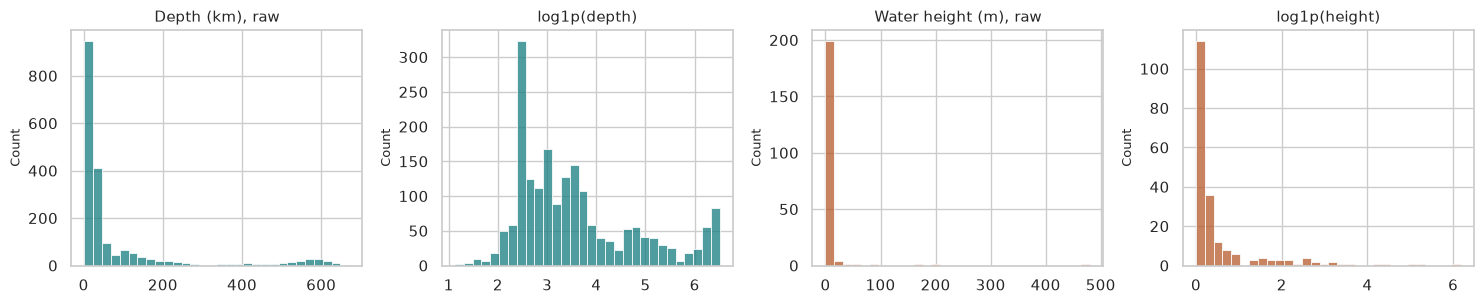

In [14]:
limits = {"magnitude": (0, 10), "depth_km": (-5, 800), "gap": (0, 360), "rms": (0, None), "dmin": (0, None)}
impossible = {c: int(((usgs_clean[c] < lo) | ((usgs_clean[c] > hi) if hi is not None else False)).sum()) for c, (lo, hi) in limits.items()}
impossible["water_height_m"] = int((noaa["water_height_m"] < 0).sum())
print("Values outside physical limits:", impossible)

rows = []
for name, frame, column in [("USGS", usgs_clean, "depth_km"), ("USGS", usgs_clean, "gap"), ("USGS", usgs_clean, "depthError"),
                            ("NOAA", noaa, "eq_depth_km"), ("NOAA", noaa, "water_height_m"), ("NOAA", noaa, "num_runups")]:
    s = frame[column].dropna()
    capped = s.clip(s.quantile(0.05), s.quantile(0.95))
    rows.append((name, column, s.skew(), np.log1p(s).skew(), capped.skew(), s.max(), capped.max()))
display(pd.DataFrame(rows, columns=["dataset", "variable", "skew raw", "skew log1p", "skew winsorized P5-P95", "max raw", "max winsorized"]).round(2))

fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
for ax, (s, title, color) in zip(axes, [
        (usgs_clean["depth_km"], "Depth (km), raw", "#167c80"), (np.log1p(usgs_clean["depth_km"]), "log1p(depth)", "#167c80"),
        (noaa["water_height_m"].dropna(), "Water height (m), raw", "#b65a2c"), (np.log1p(noaa["water_height_m"].dropna()), "log1p(height)", "#b65a2c")]):
    sns.histplot(s, bins=30, ax=ax, color=color).set(title=title, xlabel="")
plt.tight_layout(); plt.show()

## 10. Missing Values and Imputation

The mechanism decides the treatment:

| Mechanism | Meaning |
|---|---|
| **MCAR** | Missing completely at random |
| **MAR** | Missing depending on other observed variables |
| **MNAR** | Missing depending on the unobserved value |
| **Structural** | The value does not exist for that record |

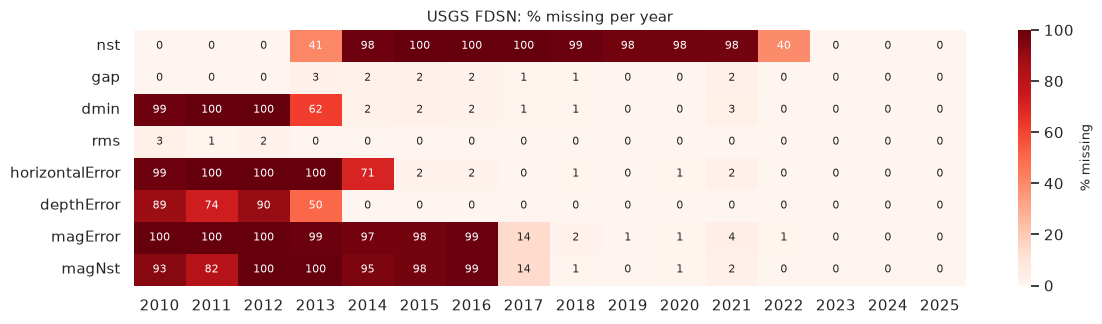

,column,missing %,Cramer's V (missing x year),p-value
0,nst,51.79,0.93,< 1e-290
1,dmin,27.79,0.94,< 1e-290
2,horizontalError,34.58,0.96,< 1e-290
3,depthError,22.50,0.86,< 1e-290
4,magError,49.71,0.97,< 1e-290
5,magNst,47.07,0.93,< 1e-290


NOAA magnitude missing by cause: {'Earthquake': '0/179', 'Eq.+landslide': '0/5', 'Landslide': '17/17', 'Meteorological': '9/9', 'Unknown': '2/2', 'Volcano': '6/6', 'Volcano+eq.': '0/1', 'Volcano+landsl.': '1/2'}


In [15]:
by_year = usgs_clean.groupby("year")[quality].agg(lambda s: 100 * s.isna().mean())
fig, ax = plt.subplots(figsize=(12, 3.4))
sns.heatmap(by_year.T, cmap="Reds", annot=True, fmt=".0f", annot_kws={"size": 8}, cbar_kws={"label": "% missing"}, ax=ax)
ax.set(title="USGS FDSN: % missing per year", xlabel="", ylabel=""); plt.tight_layout(); plt.show()

rows = []
for column in quality:
    missing = usgs_clean[column].isna()
    if 0.05 < missing.mean():
        table = pd.crosstab(missing, usgs_clean["year"])
        chi2 = stats.chi2_contingency(table)
        cramers_v = np.sqrt(chi2.statistic / (table.to_numpy().sum() * (min(table.shape) - 1)))
        rows.append((column, 100 * missing.mean(), cramers_v, chi2.pvalue))
display(pd.DataFrame(rows, columns=["column", "missing %", "Cramer's V (missing x year)", "p-value"])
        .assign(**{"p-value": lambda d: d["p-value"].map(lambda p: "< 1e-290" if p < 1e-290 else f"{p:.1e}")}).round(2))
print("NOAA magnitude missing by cause:", noaa.groupby("cause")["eq_magnitude"].apply(lambda s: f"{s.isna().sum()}/{len(s)}").to_dict())

**Reading.** The USGS quality columns are **MAR**: whether they are missing depends on the year, because the catalog changed which fields it publishes. NOAA earthquake magnitude and depth are missing only for causes other than an earthquake (**structural**), and NOAA water heights may be missing precisely for small or unmeasured tsunamis (possibly **MNAR**).

| Field | Decision | Reason |
|---|---|---|
| `nst`, `magError`, `magNst` | Drop (> 40 % missing) | Too little information, missing in whole periods |
| `dmin`, `horizontalError`, `depthError`, `gap`, `rms` | Median by depth class, with a flag | Skewed, at most 35 % missing, quality indicators only |
| NOAA magnitude and depth | Not imputed | The earthquake does not exist |
| NOAA water height | Not imputed | Measured impact, possibly MNAR |
| Coordinates and times | Not imputed | Inventing a place or a time would create false matches |

The test below hides 20 % of the known values, fills them with each strategy and compares the error. It can only use years where the column exists, so it does **not** prove the quality of the values filled for 2010–2014, and the curated columns must not be used for trends over time.

In [16]:
IMPUTE = ["dmin", "horizontalError", "depthError", "gap", "rms"]
rng = np.random.default_rng(42)
rows = []
for column in IMPUTE:
    known = usgs_clean.loc[usgs_clean[column].notna(), [column, "depth_class"]]
    errors = {"mean": [], "median": [], "median by depth class": []}
    for _ in range(30):
        hidden = rng.random(len(known)) < 0.2
        train, test = known[~hidden], known[hidden]
        groups = train.groupby("depth_class", observed=True)[column].median()
        guesses = {"mean": train[column].mean(), "median": train[column].median(),
                   "median by depth class": test["depth_class"].map(groups).astype(float)}
        for name, guess in guesses.items():
            errors[name].append((test[column] - guess).abs().mean())
    rows.append((column, usgs_clean[column].isna().sum(), *[np.mean(v) for v in errors.values()]))
test_results = pd.DataFrame(rows, columns=["column", "missing", "MAE mean", "MAE median", "MAE median by depth class"])
display(test_results.round(3))

curated_usgs = usgs_clean.copy()
for column in IMPUTE:
    curated_usgs[f"{column}_was_missing"] = curated_usgs[column].isna()
    group_median = curated_usgs.groupby("depth_class", observed=True)[column].transform("median")
    curated_usgs[f"{column}_imputed"] = curated_usgs[column].fillna(group_median)
check = pd.DataFrame({"missing before": curated_usgs[IMPUTE].isna().sum(),
                      "missing after": [curated_usgs[f"{c}_imputed"].isna().sum() for c in IMPUTE],
                      "median before": curated_usgs[IMPUTE].median(), "median after": [curated_usgs[f"{c}_imputed"].median() for c in IMPUTE],
                      "std before": curated_usgs[IMPUTE].std(), "std after": [curated_usgs[f"{c}_imputed"].std() for c in IMPUTE]})
display(check.round(3))

,column,missing,MAE mean,MAE median,MAE median by depth class
0,dmin,536,2.079,1.916,1.879
1,horizontalError,667,1.439,1.438,1.336
2,depthError,434,0.993,0.720,0.711
3,gap,16,16.717,15.484,14.875
4,rms,9,0.178,0.178,0.178


,missing before,missing after,median before,median after,std before,std after
dmin,536,0,2.045,1.851,3.739,3.220
horizontalError,667,0,6.900,6.680,1.898,1.573
depthError,434,0,1.800,1.800,2.178,1.932
gap,16,0,25.000,25.000,24.931,24.836
rms,9,0,0.900,0.900,0.228,0.227


## 11. Feature Engineering

- **Transforms**: log1p of depth, gap and error columns; log1p of water height and run-ups.
- **Derived features**: radiated energy (Gutenberg–Richter, log10 E = 1.5 M + 4.8, joules), depth and magnitude class, year and month, 10° region cell as in Gold, and whether the cause of a tsunami is an earthquake.
- **Encoding**: ordinal for the classes, one-hot for the magnitude type with rare types grouped.
- **Scaling**: standard scores for the numeric features (comparison only, originals are kept).

In [17]:
f = curated_usgs
f["log_depth"] = np.log1p(f["depth_km"])
f["lon360"] = f["longitude"].where(f["longitude"] >= 0, f["longitude"] + 360)  # continuous across the antimeridian
for column in ["gap", "dmin", "horizontalError", "depthError"]:
    f[f"log_{column}"] = np.log1p(f[f"{column}_imputed"])
f["log10_energy_j"] = 1.5 * f["magnitude"] + 4.8
f["depth_class_code"] = f["depth_class"].cat.codes
f["magnitude_class_code"] = f["magnitude_class"].cat.codes
f["month"] = f["time"].dt.month
f["region_cell"] = ((np.floor(f["latitude"] / 10) * 10).astype(int).astype(str) + ".."
                    + (np.floor(f["latitude"] / 10) * 10 + 10).astype(int).astype(str) + " lat, "
                    + (np.floor(f["longitude"] / 10) * 10).astype(int).astype(str) + ".."
                    + (np.floor(f["longitude"] / 10) * 10 + 10).astype(int).astype(str) + " lon")
counts = f["magnitude_type"].value_counts()
f["magnitude_type_group"] = f["magnitude_type"].where(f["magnitude_type"].map(counts) >= 50, "other")
dummies = pd.get_dummies(f["magnitude_type_group"], prefix="magtype", dtype=int)
f = pd.concat([f, dummies], axis=1)

t = noaa.copy()
t["log_water_height"] = np.log1p(t["water_height_m"])
t["log_runups"] = np.log1p(t["num_runups"])
t["log_eq_depth"] = np.log1p(t["eq_depth_km"])
t["earthquake_cause"] = t["cause_code"].isin([1, 3, 4])
t["reliable"] = t["validity"].isin([3, 4])
t["full_time"] = t["second"].notna()

FEATURES = ["magnitude", "log10_energy_j", "depth_km", "log_depth", "depth_class_code", "magnitude_class_code", "latitude",
            "lon360", "year", "month", "log_gap", "rms_imputed", "log_dmin", "log_horizontalError", "log_depthError"] + list(dummies)
scaled = (f[FEATURES] - f[FEATURES].mean()) / f[FEATURES].std()
print(f"USGS features: {len(FEATURES)} | magnitude types after grouping: {f['magnitude_type_group'].value_counts().to_dict()}")
display(scaled[FEATURES[:6]].agg(["mean", "std"]).round(3))
print("NOAA flags:", {c: int(t[c].sum()) for c in ["earthquake_cause", "reliable", "full_time"]})

USGS features: 20 | magnitude types after grouping: {'mww': 1651, 'mwc': 137, 'mb': 64, 'mwb': 51, 'other': 26}


,magnitude,log10_energy_j,depth_km,log_depth,depth_class_code,magnitude_class_code
mean,0.0,-0.0,-0.0,-0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0


NOAA flags: {'earthquake_cause': 185, 'reliable': 212, 'full_time': 189}


## 12. Feature Selection

Filter methods only (no wrapper or embedded model): drop columns with more than 40 % missing values, near-constant columns, and one of each pair with |Spearman| > 0.9. The variance inflation factor (VIF) then checks the remaining set for multicollinearity.

,reason
dropped,
nst,more than 40% missing
magError,more than 40% missing
magNst,more than 40% missing
magtype_mb,near constant (97% one value)
magtype_mwb,near constant (97% one value)
magtype_other,near constant (99% one value)
log10_energy_j,|rho| = 1.00 with magnitude
depth_km,|rho| = 1.00 with log_depth
magtype_mww,reference category of the one-hot encoding


Pairs still above 0.9: none


,VIF before,VIF selected
magnitude,5.86,1.11
magnitude_class_code,5.77,NaN
log_depth,5.61,1.26
depth_class_code,5.48,NaN
log_gap,1.54,1.54
year,1.43,1.43
log_horizontalError,1.38,1.38
lon360,1.38,1.37
log_dmin,1.36,1.33
latitude,1.26,1.25


Selected 12 of 20 features: magnitude, log_depth, latitude, lon360, year, month, log_gap, rms_imputed, log_dmin, log_horizontalError, log_depthError, magtype_mwc


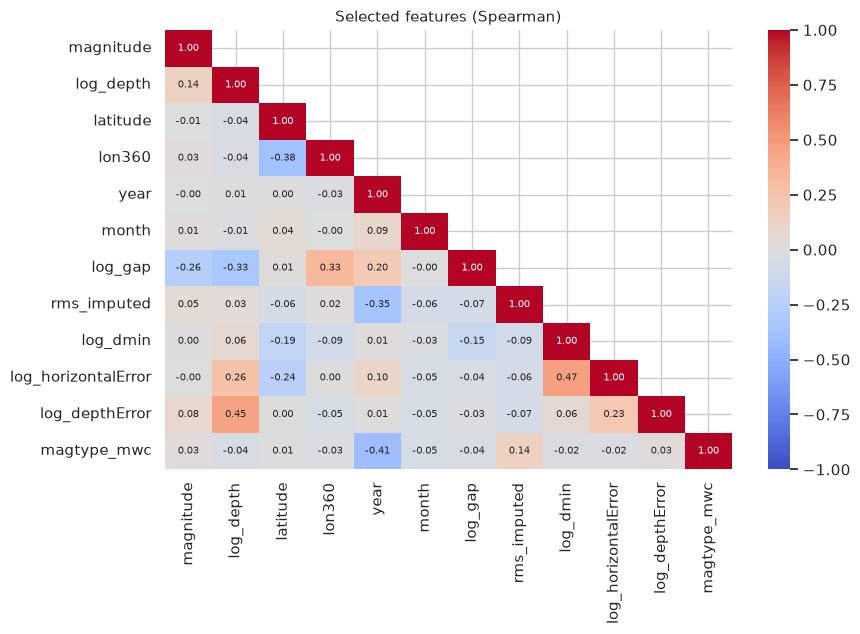

In [18]:
dropped = {c: "more than 40% missing" for c in quality if usgs_clean[c].isna().mean() > 0.4}
for column in FEATURES:
    top_share = f[column].value_counts(normalize=True).iloc[0]
    if f[column].nunique() <= 2 and top_share > 0.95:
        dropped[column] = f"near constant ({top_share:.0%} one value)"
candidates = [c for c in FEATURES if c not in dropped]
corr = f[candidates].corr(method="spearman").abs()
# In each redundant pair keep the feature that is easier to interpret (listed first)
for keep, drop in [("magnitude", "log10_energy_j"), ("log_depth", "depth_km")]:
    if corr.loc[keep, drop] > 0.9:
        dropped[drop] = f"|rho| = {corr.loc[keep, drop]:.2f} with {keep}"
selected = [c for c in candidates if c not in dropped]
if any(c.startswith("magtype_") for c in selected):
    reference = "magtype_mww"          # reference category of the one-hot encoding
    if reference in selected:
        selected.remove(reference); dropped[reference] = "reference category of the one-hot encoding"
display(pd.Series(dropped, name="reason").rename_axis("dropped").to_frame())
remaining = f[selected].corr(method="spearman").abs()
pairs_left = [(a, b, round(remaining.loc[a, b], 2)) for i, a in enumerate(selected) for b in selected[i + 1:] if remaining.loc[a, b] > 0.9]
print("Pairs still above 0.9:", pairs_left or "none")


def vif(frame):
    inverse = np.linalg.inv(np.corrcoef(frame.to_numpy(dtype=float).T))
    return pd.Series(np.diag(inverse), index=frame.columns).round(2).sort_values(ascending=False)


vif_before = vif(f[selected])
for code_column, parent in [("depth_class_code", "log_depth"), ("magnitude_class_code", "magnitude")]:
    if code_column in selected and vif_before[code_column] > 5:
        selected.remove(code_column); dropped[code_column] = f"VIF {vif_before[code_column]} (class of {parent})"
display(pd.DataFrame({"VIF before": vif_before, "VIF selected": vif(f[selected])}).sort_values("VIF before", ascending=False))
print(f"Selected {len(selected)} of {len(FEATURES)} features:", ", ".join(selected))

fig, ax = plt.subplots(figsize=(9, 6.5))
c = f[selected].corr(method="spearman")
sns.heatmap(c, mask=np.triu(np.ones_like(c, dtype=bool), k=1), annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, annot_kws={"size": 7}, ax=ax)
ax.set_title("Selected features (Spearman)"); plt.tight_layout(); plt.show()

## 13. Curated Layer

The curated files keep the original values, the imputed copies with their flags, and the selected features. They are written next to the Silver samples and do not replace the Silver topics used by the pipeline.

In [19]:
out = root / "datalake_silver" / "samples" / "curated"
out.mkdir(parents=True, exist_ok=True)
keep = ["id", "time", "place", "magnitude_type", "depth_km", "region_cell", "depth_class", "magnitude_class"]
keep += IMPUTE + [f"{c}_imputed" for c in IMPUTE] + [f"{c}_was_missing" for c in IMPUTE]
usgs_out = f[list(dict.fromkeys(keep + selected))].rename(columns={"id": "external_id", "time": "event_time"})
noaa_out = t.rename(columns={"id": "external_id"})
noaa_out["external_id"] = noaa_out["external_id"].astype(str)
for name, frame in [("earthquakes_curated", usgs_out), ("tsunamis_curated", noaa_out)]:
    frame.to_parquet(out / f"{name}.parquet", index=False, coerce_timestamps="us", allow_truncated_timestamps=True)
    back = pd.read_parquet(out / f"{name}.parquet")
    assert len(back) == len(frame) and back["external_id"].is_unique
    print(f"{name}.parquet: {back.shape[0]:,} rows x {back.shape[1]} columns, ids unique")
print("Imputed columns without missing values:", not usgs_out[[f"{c}_imputed" for c in IMPUTE]].isna().any().any())

earthquakes_curated.parquet: 1,929 rows x 34 columns, ids unique
tsunamis_curated.parquet: 221 rows x 24 columns, ids unique
Imputed columns without missing values: True


## 14. Summary

| Step | Action |
|---|---|
| Raw data | One committed Bronze run, 2010–2025 |
| EDA and profiling | Types, missing map, univariate, descriptive, shape, bivariate and multivariate analysis |
| Outlier detection | Z-score, IQR and Mahalanobis distance |
| Outlier treatment | Non-earthquake record removed, real extremes kept, log1p for skewed variables |
| Imputation | Mechanisms analysed; group median with flags for quality columns only |
| Feature engineering | Transforms, derived features, encoding and scaling |
| Feature selection | Missing-value, near-constant, correlation and VIF filters |
| Curated layer | Two Parquet files, separate from the operational Silver topics |

**Limitations.** Imputed quality values for 2010–2014 cannot be verified; correlations describe the selected catalogs and not causes; the Mahalanobis distance assumes approximately elliptical data after the transforms; and the NOAA height–magnitude relation uses only events where both were reported.